# 11 — Infer building RES / NRES from GHSL (step by step)

**What this notebook does.** Walk through how to assign a **residential vs non-residential**
label to a building footprint using **GHS-BUILT-C FUN** (R2023A, 10 m, ESRI:54009).

This is the same aggregation used in `validation/building_eval.py`. GHSL does **not**
produce fine types (house vs office vs school) — only binary function codes:

| Raster value | Meaning |
|---|---|
| `0` | non-built |
| `1` | residential |
| `2` | non-residential |
| `255` | nodata |

**Recipe (one building)**

```text
1. Load footprint polygon
2. Reproject to ESRI:54009 (GHSL CRS) — never invent a new 10 m grid
3. Open the covering GHS-BUILT-C FUN tile
4. Read a small window around the footprint (nearest-neighbor only)
5. Rasterize the footprint onto that window → pixel mask
6. Collect GHSL codes under the mask
7. Majority vote among {1, 2} → RES or NRES
   (if neither present → NONBUILT / NODATA = abstain)
```

**Not GT.** Locked study labels remain Overture `resi_def_v1`. GHSL here is a
*predictor / baseline*, the same role as in the validation pipeline.

**Writes.** `outputs/ghsl_inference/` (figures, per-building table, `snapshot.json`).


## 0. Setup


In [16]:
from __future__ import annotations

import json
import os
import sys
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

%matplotlib inline

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio import features
from rasterio.transform import rowcol
from rasterio.windows import Window, from_bounds
from shapely import wkt as shapely_wkt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

ROOT = Path(".").resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "validation" / "config.yaml").exists():
        ROOT = cand
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from validation.ghsl import open_ghsl
from validation.io import load_config, load_gt_buildings

CFG = load_config(ROOT / "validation" / "config.yaml")
OUT = ROOT / "outputs" / "ghsl_inference"
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

GHSL_CRS = "ESRI:54009"
RES_V = int(CFG["ghsl"]["residential_value"])       # 1
NRES_V = int(CFG["ghsl"]["non_residential_value"])  # 2
NON_V = int(CFG["ghsl"]["nonbuilt_value"])          # 0
NOD_V = int(CFG["ghsl"]["nodata_value"])            # 255

CMAP = ListedColormap(["#f0f0f0", "#2ca02c", "#d62728", "#333333"])  # 0,1,2,255→idx
CODE_TO_IDX = {0: 0, 1: 1, 2: 2, 255: 3}

print("ROOT", ROOT)
print("tiles", Path(CFG["paths"]["ghsl_tiles_dir"]).resolve())
print("GHSL codes: RES=", RES_V, "NRES=", NRES_V, "NONBUILT=", NON_V, "NODATA=", NOD_V)


ROOT /data/users/kv133/Alpha-Earth-Embeddings-Research
tiles /data/users/kv133/Alpha-Earth-Embeddings-Research/data/ghsl/tiles
GHSL codes: RES= 1 NRES= 2 NONBUILT= 0 NODATA= 255


## 1. Load a few GT buildings (for illustration)

We sample one **RES** and one **NRES** footprint from an AOI covered by local tiles.
Overture GT is shown only so you can see agreement / disagreement — it is **not** used
to compute the GHSL prediction.


In [17]:
gt = load_gt_buildings(CFG["paths"]["gt_buildings"], CFG)
print("GT buildings:", len(gt), "AOIs:", sorted(gt["aoi_id"].astype(str).unique()))

# Prefer NYC (covered by existing CONUS tiles); fall back to first AOI
preferred = "NYC_NE"
aoi = preferred if preferred in set(gt["aoi_id"].astype(str)) else str(gt["aoi_id"].iloc[0])
sub = gt[gt["aoi_id"].astype(str) == aoi].copy()

# One RES + one NRES with non-empty geometry
examples = []
for lab in ("RES", "NRES"):
    hit = sub[sub["label"].astype(str) == lab]
    if len(hit) == 0:
        continue
    # Prefer mid-area buildings (neither tiny nor stadium-scale)
    areas = hit.geometry.to_crs(GHSL_CRS).area
    order = areas.sort_values().index
    pick = hit.loc[order[len(order) // 2]]
    examples.append(pick)

demo = gpd.GeoDataFrame(examples, crs=gt.crs).reset_index(drop=True)
demo_m = demo.to_crs(GHSL_CRS)
display(demo[["building_id", "aoi_id", "label"]])
print("Mollweide bounds of demo set:", demo_m.total_bounds)


GT buildings: 11280 AOIs: ['Atlanta_SE', 'Boston_NE', 'Chicago_MW', 'Denver_W', 'Houston_S', 'LA_W', 'NYC_NE', 'Phoenix_SW', 'SF_W', 'Seattle_NW']


,building_id,aoi_id,label
0,b5c61307-5190-413f-bc2a-640dd65ef84d,NYC_NE,RES
1,7287d16e-f328-4614-b15b-1c5ad185f016,NYC_NE,NRES


Mollweide bounds of demo set: [-6237601.80830325  4866102.97673073 -6236890.59714852  4876870.63384273]


## 2. Core function — GHSL label for one polygon

Same logic as `validation.building_eval._ghsl_label_for_geom`:

1. Window the GHSL tile around the footprint.
2. Rasterize the polygon onto that window (`all_touched=False`).
3. If the mask is empty (skinny footprint), fall back to the **centroid** pixel.
4. Majority among residential (`1`) vs non-residential (`2`) pixels.


In [18]:
def majority_from_values(vals: np.ndarray) -> tuple[str, dict]:
    """Map GHSL codes under a footprint → RES / NRES / NONBUILT / NODATA."""
    empty = {
        "n_pixels": 0,
        "n_res": 0,
        "n_nres": 0,
        "n_nonbuilt": 0,
        "n_nodata": 0,
        "frac_res": 0.0,
        "frac_nres": 0.0,
    }
    if vals.size == 0:
        return "NODATA", empty
    n_res = int(np.sum(vals == RES_V))
    n_nres = int(np.sum(vals == NRES_V))
    n_non = int(np.sum(vals == NON_V))
    n_nod = int(np.sum(vals == NOD_V))
    stats = {
        "n_pixels": int(vals.size),
        "n_res": n_res,
        "n_nres": n_nres,
        "n_nonbuilt": n_non,
        "n_nodata": n_nod,
        "frac_res": n_res / vals.size,
        "frac_nres": n_nres / vals.size,
    }
    if n_res == 0 and n_nres == 0:
        return ("NONBUILT" if n_non > 0 else "NODATA"), stats
    # Tie → RES (matches validation/building_eval.py: n_res >= n_nres)
    return ("RES" if n_res >= n_nres else "NRES"), stats


def infer_building_from_ghsl(geom, ds) -> tuple[str, dict, dict]:
    """Return (label, stats, debug) for one Shapely geom in GHSL CRS.

    debug holds the window arrays used for plotting.
    """
    empty_dbg = {"data": None, "mask": None, "transform": None}
    if geom is None or geom.is_empty:
        return "NODATA", majority_from_values(np.array([]))[1], empty_dbg

    minx, miny, maxx, maxy = geom.bounds
    window = from_bounds(minx, miny, maxx, maxy, transform=ds.transform)
    window = Window(
        max(0, int(window.col_off) - 2),
        max(0, int(window.row_off) - 2),
        max(1, int(np.ceil(window.width)) + 4),
        max(1, int(np.ceil(window.height)) + 4),
    ).intersection(Window(0, 0, ds.width, ds.height))
    if window.width <= 0 or window.height <= 0:
        return "NODATA", majority_from_values(np.array([]))[1], empty_dbg

    # CRITICAL: nearest only — never bilinear on a categorical raster
    data = ds.read(1, window=window)
    transform = ds.window_transform(window)
    mask = features.rasterize(
        [(geom, 1)],
        out_shape=data.shape,
        transform=transform,
        fill=0,
        dtype=np.uint8,
        all_touched=False,
    )
    vals = data[mask == 1]
    used_centroid_fallback = False
    if vals.size == 0:
        c = geom.centroid
        try:
            rr, cc = rowcol(transform, c.x, c.y)
            if 0 <= rr < data.shape[0] and 0 <= cc < data.shape[1]:
                vals = np.array([data[rr, cc]])
                used_centroid_fallback = True
        except Exception:
            vals = np.array([], dtype=data.dtype)

    label, stats = majority_from_values(vals)
    stats["centroid_fallback"] = used_centroid_fallback
    debug = {"data": data, "mask": mask, "transform": transform, "vals": vals}
    return label, stats, debug


print("Helpers ready.")


Helpers ready.


## 3. Worked example — one building, every intermediate array

For each demo footprint we:

1. Find the covering tile.
2. Run `infer_building_from_ghsl`.
3. Plot footprint outline on the GHSL window + the binary mask + value histogram.


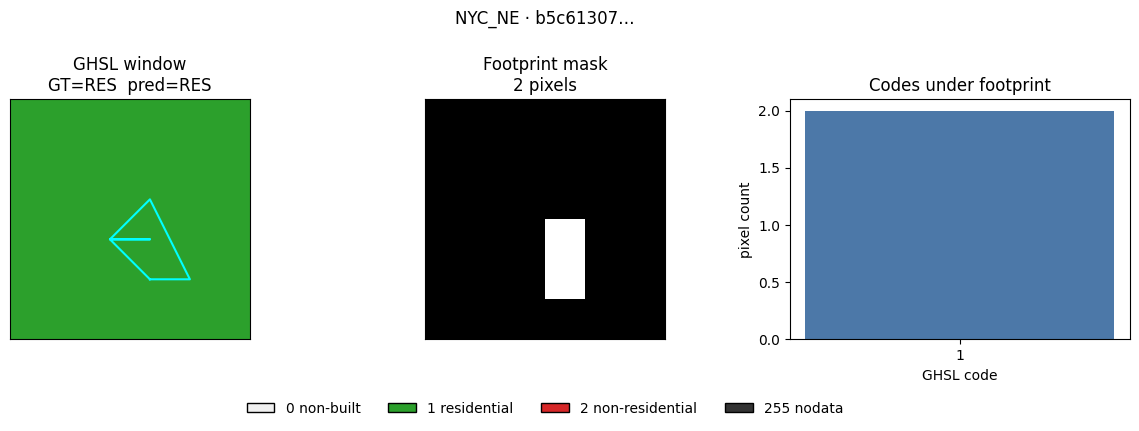

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/figures/example_res_b5c61307.png


**Decision:** `2` RES px vs `0` NRES px → **`RES`** · agrees with GT=`RES`

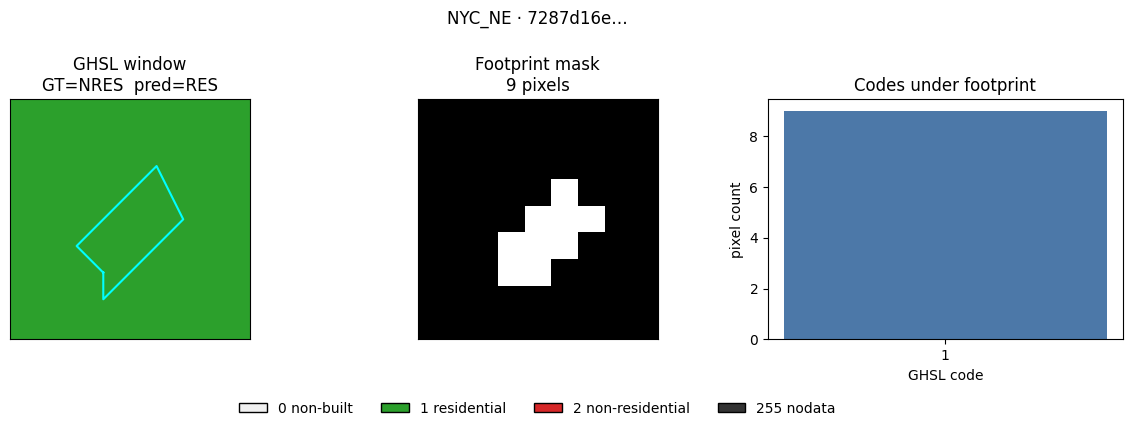

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/figures/example_nres_7287d16e.png


**Decision:** `9` RES px vs `0` NRES px → **`RES`** · disagrees with GT=`NRES`

,building_id,aoi_id,gt_label,ghsl_prediction,agree,tile,n_pixels,n_res,n_nres,n_nonbuilt,n_nodata,frac_res,frac_nres,centroid_fallback
0,b5c61307-5190-413f-bc2a-640dd65ef84d,NYC_NE,RES,RES,True,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,2,2,0,0,0,1.0000,0.0000,False
1,7287d16e-f328-4614-b15b-1c5ad185f016,NYC_NE,NRES,RES,False,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,9,9,0,0,0,1.0000,0.0000,False


In [19]:
mosaic = open_ghsl(CFG)

def covering_ds(geom):
    minx, miny, maxx, maxy = geom.bounds
    hits = mosaic.datasets_for_bounds(minx, miny, maxx, maxy)
    if not hits:
        c = geom.centroid
        hits = mosaic.datasets_for_bounds(c.x, c.y, c.x, c.y)
    return hits[0] if hits else None


rows = []
for i, row in demo_m.iterrows():
    geom = row.geometry
    ds = covering_ds(geom)
    if ds is None:
        print("No tile for", row["building_id"])
        continue
    pred, stats, dbg = infer_building_from_ghsl(geom, ds)
    agree = pred == str(row["label"]) if pred in ("RES", "NRES") else None
    rec = {
        "building_id": row["building_id"],
        "aoi_id": row["aoi_id"],
        "gt_label": row["label"],
        "ghsl_prediction": pred,
        "agree": agree,
        "tile": Path(ds.name).name if hasattr(ds, "name") else str(ds),
        **{k: stats[k] for k in ("n_pixels", "n_res", "n_nres", "n_nonbuilt", "n_nodata",
                                  "frac_res", "frac_nres", "centroid_fallback")},
    }
    rows.append(rec)

    # --- figure: GHSL window / mask / histogram ---
    data, mask = dbg["data"], dbg["mask"]
    show = np.vectorize(lambda v: CODE_TO_IDX.get(int(v), 3))(data).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    ax = axes[0]
    ax.imshow(show, cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
    # footprint outline in pixel coords
    xs, ys = [], []
    if geom.geom_type == "Polygon":
        rings = [geom.exterior]
    else:
        rings = [p.exterior for p in geom.geoms]
    for ring in rings:
        for x, y in ring.coords:
            r, c = rowcol(dbg["transform"], x, y)
            xs.append(c)
            ys.append(r)
        ax.plot(xs, ys, color="cyan", lw=1.5)
        xs, ys = [], []
    ax.set_title(f"GHSL window\nGT={row['label']}  pred={pred}")
    ax.set_xticks([]); ax.set_yticks([])

    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1].set_title(f"Footprint mask\n{stats['n_pixels']} pixels")
    axes[1].set_xticks([]); axes[1].set_yticks([])

    codes, counts = np.unique(dbg["vals"], return_counts=True) if dbg["vals"].size else ([], [])
    axes[2].bar([str(int(c)) for c in codes], counts, color="#4c78a8")
    axes[2].set_xlabel("GHSL code")
    axes[2].set_ylabel("pixel count")
    axes[2].set_title("Codes under footprint")

    fig.legend(
        handles=[
            Patch(facecolor="#f0f0f0", edgecolor="k", label="0 non-built"),
            Patch(facecolor="#2ca02c", edgecolor="k", label="1 residential"),
            Patch(facecolor="#d62728", edgecolor="k", label="2 non-residential"),
            Patch(facecolor="#333333", edgecolor="k", label="255 nodata"),
        ],
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, -0.08),
        frameon=False,
    )
    fig.suptitle(f"{row['aoi_id']} · {row['building_id'][:8]}…", y=1.02)
    fig.tight_layout()
    out_png = FIG / f"example_{row['label'].lower()}_{row['building_id'][:8]}.png"
    fig.savefig(out_png, dpi=140, bbox_inches="tight")
    plt.show()
    print("Wrote", out_png)
    display(Markdown(
        f"**Decision:** `{stats['n_res']}` RES px vs `{stats['n_nres']}` NRES px "
        f"→ **`{pred}`**"
        + (" (centroid fallback)" if stats["centroid_fallback"] else "")
        + (f" · agrees with GT=`{row['label']}`" if agree else f" · disagrees with GT=`{row['label']}`"
           if agree is False else " · abstained")
    ))

demo_table = pd.DataFrame(rows)
display(demo_table)


## 3b. Mixed GHSL under one footprint (not a single value)

Many buildings cover **more than one** GHS-BUILT-C code (e.g. both `1` and `2`).
That is exactly when majority vote matters. Below we search the AOI for footprints
whose mask has ≥2 distinct codes in `{0,1,2}`, prefer cases with **both RES and NRES
pixels**, and plot:

1. Full GHSL window + outline  
2. **Codes only under the footprint** (outside masked out) — so the mix is obvious  
3. Pixel-count bar for the mix + majority decision


scan mixed:   0%|          | 0/1327 [00:00<?, ?it/s]

Mixed footprints in NYC_NE: 425 / 1327


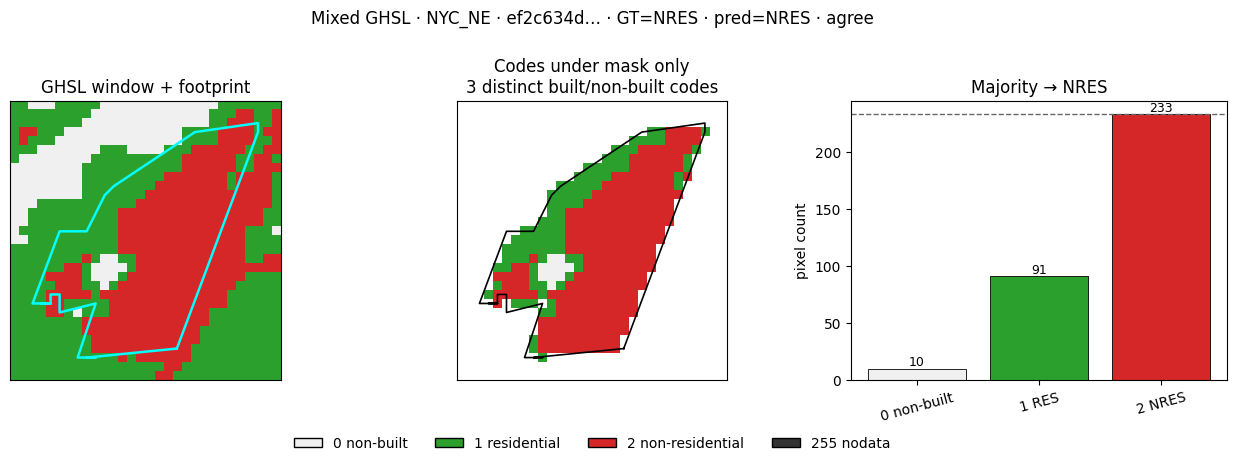

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/figures/mixed_ef2c634d.png


**Mixed decision for `ef2c634d…`:** `91` RES + `233` NRES + `10` non-built → majority **`NRES`** (GT=`NRES`, agree)

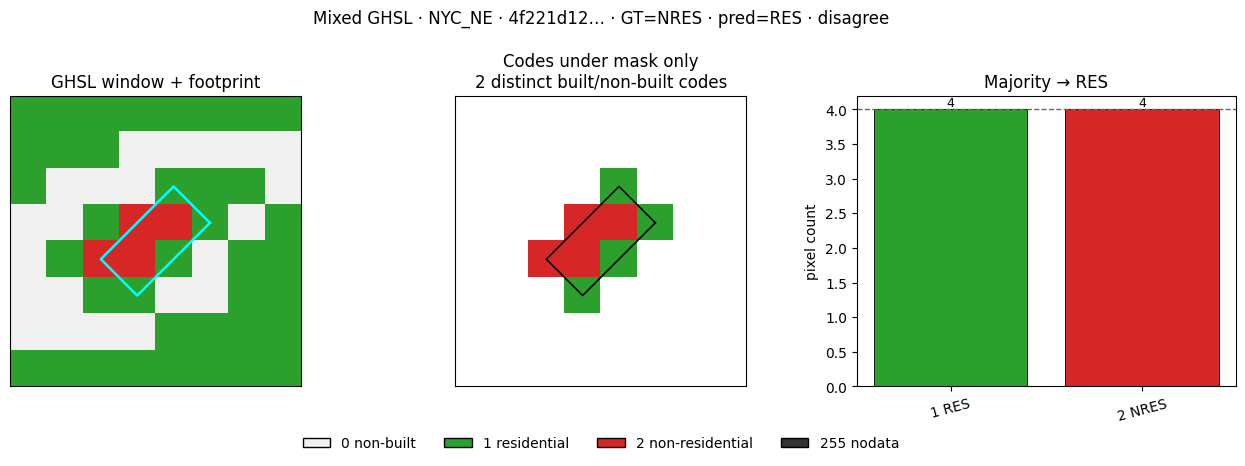

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/figures/mixed_4f221d12.png


**Mixed decision for `4f221d12…`:** `4` RES + `4` NRES + `0` non-built → majority **`RES`** (GT=`NRES`, **disagree**)

,building_id,aoi_id,gt_label,ghsl_prediction,n_pixels,n_res,n_nres,n_nonbuilt,n_codes,balance_12,minority_frac,agree
0,ef2c634d-4e2c-4977-854b-77c81da140fa,NYC_NE,NRES,NRES,334,91,233,10,3,91,0.2725,True
1,4f221d12-8f9b-4462-bf6e-1d1a0fd0395a,NYC_NE,NRES,RES,8,4,4,0,2,4,0.5000,False


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/mixed_examples.parquet n= 425


In [20]:
def _outline_pix(ax, geom, transform, color="cyan", lw=1.8):
    rings = [geom.exterior] if geom.geom_type == "Polygon" else [p.exterior for p in geom.geoms]
    for ring in rings:
        xs, ys = [], []
        for x, y in ring.coords:
            rr, cc = rowcol(transform, x, y)
            xs.append(cc)
            ys.append(rr)
        ax.plot(xs, ys, color=color, lw=lw)


def plot_mixed_footprint(geom, gt_label, building_id, aoi_id, ds, out_png: Path):
    pred, stats, dbg = infer_building_from_ghsl(geom, ds)
    data, mask, transform, vals = dbg["data"], dbg["mask"], dbg["transform"], dbg["vals"]
    show = np.vectorize(lambda v: CODE_TO_IDX.get(int(v), 3))(data).astype(np.uint8)

    # Panel 2: GHSL codes *only* inside the footprint (outside → NaN / white)
    under = np.full(data.shape, np.nan, dtype=float)
    under[mask == 1] = np.vectorize(lambda v: CODE_TO_IDX.get(int(v), 3))(data[mask == 1])

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

    axes[0].imshow(show, cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
    _outline_pix(axes[0], geom, transform)
    axes[0].set_title("GHSL window + footprint")
    axes[0].set_xticks([]); axes[0].set_yticks([])

    axes[1].imshow(under, cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
    _outline_pix(axes[1], geom, transform, color="black", lw=1.2)
    n_codes = sum(1 for k in ("n_res", "n_nres", "n_nonbuilt") if stats[k] > 0)
    axes[1].set_title(f"Codes under mask only\n{n_codes} distinct built/non-built codes")
    axes[1].set_xticks([]); axes[1].set_yticks([])

    labels = ["0 non-built", "1 RES", "2 NRES", "255 nodata"]
    counts = [stats["n_nonbuilt"], stats["n_res"], stats["n_nres"], stats["n_nodata"]]
    colors = ["#f0f0f0", "#2ca02c", "#d62728", "#333333"]
    present = [(lab, c, col) for lab, c, col in zip(labels, counts, colors) if c > 0]
    axes[2].bar([p[0] for p in present], [p[1] for p in present], color=[p[2] for p in present],
                edgecolor="k", linewidth=0.6)
    axes[2].axhline(max(stats["n_res"], stats["n_nres"]), color="0.4", ls="--", lw=1,
                    label="majority among {1,2}")
    axes[2].set_ylabel("pixel count")
    axes[2].set_title(f"Majority → {pred}")
    axes[2].tick_params(axis="x", rotation=15)
    for i, (_, c, _) in enumerate(present):
        axes[2].text(i, c, str(c), ha="center", va="bottom", fontsize=9)

    agree = pred == str(gt_label) if pred in ("RES", "NRES") else None
    fig.suptitle(
        f"Mixed GHSL · {aoi_id} · {building_id[:8]}… · GT={gt_label} · pred={pred}"
        + (f" · {'agree' if agree else 'disagree'}" if agree is not None else ""),
        y=1.02,
    )
    fig.legend(
        handles=[
            Patch(facecolor="#f0f0f0", edgecolor="k", label="0 non-built"),
            Patch(facecolor="#2ca02c", edgecolor="k", label="1 residential"),
            Patch(facecolor="#d62728", edgecolor="k", label="2 non-residential"),
            Patch(facecolor="#333333", edgecolor="k", label="255 nodata"),
        ],
        loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06), frameon=False,
    )
    fig.tight_layout()
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.show()
    return pred, stats, agree


# Scan AOI for mixed masks; keep top RES∩NRES and one 3-code example
mixed_hits = []
scan = sub.to_crs(GHSL_CRS)
for _, r in tqdm(scan.iterrows(), total=len(scan), desc="scan mixed"):
    geom = r.geometry
    ds = covering_ds(geom)
    if ds is None:
        continue
    pred, stats, dbg = infer_building_from_ghsl(geom, ds)
    if stats["n_pixels"] < 6:
        continue
    n_codes = sum(1 for k in ("n_res", "n_nres", "n_nonbuilt") if stats[k] > 0)
    if n_codes < 2:
        continue
    mixed_hits.append({
        "building_id": r["building_id"],
        "aoi_id": r["aoi_id"],
        "gt_label": str(r["label"]),
        "ghsl_prediction": pred,
        "n_pixels": stats["n_pixels"],
        "n_res": stats["n_res"],
        "n_nres": stats["n_nres"],
        "n_nonbuilt": stats["n_nonbuilt"],
        "n_codes": n_codes,
        "balance_12": min(stats["n_res"], stats["n_nres"]),
        "minority_frac": (
            min(stats["n_res"], stats["n_nres"]) / stats["n_pixels"]
            if stats["n_res"] and stats["n_nres"] else 0.0
        ),
    })

mixed_df = pd.DataFrame(mixed_hits)
print(f"Mixed footprints in {aoi}: {len(mixed_df)} / {len(scan)}")
if len(mixed_df) == 0:
    display(Markdown("_No mixed footprints found in this AOI/tile set._"))
else:
    both = mixed_df[(mixed_df["n_res"] > 0) & (mixed_df["n_nres"] > 0)].sort_values(
        ["balance_12", "n_pixels"], ascending=False
    )
    three = mixed_df[mixed_df["n_codes"] >= 3].sort_values("n_pixels", ascending=False)
    # pick: (1) most balanced RES vs NRES, (2) largest 3-code mix, (3) near-tie if different
    picks = []
    if len(both):
        picks.append(both.iloc[0])
    if len(both) > 1:
        near = both.sort_values("minority_frac", ascending=False).iloc[0]
        if near["building_id"] not in {p["building_id"] for p in picks}:
            picks.append(near)
    if len(three):
        t0 = three.iloc[0]
        if t0["building_id"] not in {p["building_id"] for p in picks}:
            picks.append(t0)
    picks = picks[:3]

    mixed_rows = []
    for pick in picks:
        bid = pick["building_id"]
        row = scan[scan["building_id"] == bid].iloc[0]
        ds = covering_ds(row.geometry)
        out_png = FIG / f"mixed_{bid[:8]}.png"
        pred, stats, agree = plot_mixed_footprint(
            row.geometry, row["label"], bid, row["aoi_id"], ds, out_png
        )
        print("Wrote", out_png)
        display(Markdown(
            f"**Mixed decision for `{bid[:8]}…`:** "
            f"`{stats['n_res']}` RES + `{stats['n_nres']}` NRES + `{stats['n_nonbuilt']}` non-built "
            f"→ majority **`{pred}`** "
            f"(GT=`{row['label']}`"
            + (f", {'agree' if agree else '**disagree**'}" if agree is not None else "")
            + ")"
        ))
        mixed_rows.append({**pick.to_dict(), "agree": agree})

    mixed_table = pd.DataFrame(mixed_rows)
    display(mixed_table)
    mixed_path = OUT / "mixed_examples.parquet"
    mixed_df.to_parquet(mixed_path, index=False)
    print("Wrote", mixed_path, "n=", len(mixed_df))


## 4. Batch a stratified sample (parallel)

Run the same inference on a few hundred buildings from the preferred AOI so you can
see coverage and agreement rates. Uses all CPU cores via `ProcessPoolExecutor`.


In [21]:
N_SAMPLE = 400  # keep the demo fast; raise if you want full AOI
rng = np.random.default_rng(42)

pool = sub.copy()
# Stratify RES / NRES
parts = []
for lab, g in pool.groupby(pool["label"].astype(str)):
    k = min(N_SAMPLE // 2, len(g))
    parts.append(g.sample(n=k, random_state=42))
sample = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=gt.crs)
sample_m = sample.to_crs(GHSL_CRS)
print(f"Sample n={len(sample_m)} from {aoi}:", sample_m["label"].value_counts().to_dict())


def _worker(payload):
    """One process opens the mosaic and scores a chunk of buildings."""
    import geopandas as gpd
    from validation.ghsl import open_ghsl
    from validation.io import load_config

    parquet_bytes, cfg_path = payload
    import io
    gdf = gpd.read_parquet(io.BytesIO(parquet_bytes))
    cfg = load_config(cfg_path)
    mosaic = open_ghsl(cfg)
    out = []
    try:
        for _, r in gdf.iterrows():
            geom = r.geometry
            hits = mosaic.datasets_for_bounds(*geom.bounds)
            if not hits:
                c = geom.centroid
                hits = mosaic.datasets_for_bounds(c.x, c.y, c.x, c.y)
            if not hits:
                pred, stats = "NODATA", {
                    "n_pixels": 0, "n_res": 0, "n_nres": 0,
                    "n_nonbuilt": 0, "n_nodata": 0,
                    "frac_res": 0.0, "frac_nres": 0.0, "centroid_fallback": False,
                }
            else:
                # Inline majority (avoid pickling nested notebook fns)
                from rasterio import features as _f
                from rasterio.transform import rowcol as _rc
                from rasterio.windows import Window as _W, from_bounds as _fb
                import numpy as _np
                ds = hits[0]
                minx, miny, maxx, maxy = geom.bounds
                window = _fb(minx, miny, maxx, maxy, transform=ds.transform)
                window = _W(
                    max(0, int(window.col_off) - 2),
                    max(0, int(window.row_off) - 2),
                    max(1, int(_np.ceil(window.width)) + 4),
                    max(1, int(_np.ceil(window.height)) + 4),
                ).intersection(_W(0, 0, ds.width, ds.height))
                data = ds.read(1, window=window)
                transform = ds.window_transform(window)
                mask = _f.rasterize(
                    [(geom, 1)], out_shape=data.shape, transform=transform,
                    fill=0, dtype=_np.uint8, all_touched=False,
                )
                vals = data[mask == 1]
                fb = False
                if vals.size == 0:
                    c = geom.centroid
                    try:
                        rr, cc = _rc(transform, c.x, c.y)
                        if 0 <= rr < data.shape[0] and 0 <= cc < data.shape[1]:
                            vals = _np.array([data[rr, cc]])
                            fb = True
                    except Exception:
                        vals = _np.array([], dtype=data.dtype)
                n_res = int(_np.sum(vals == 1))
                n_nres = int(_np.sum(vals == 2))
                n_non = int(_np.sum(vals == 0))
                n_nod = int(_np.sum(vals == 255))
                if vals.size == 0:
                    pred = "NODATA"
                elif n_res == 0 and n_nres == 0:
                    pred = "NONBUILT" if n_non > 0 else "NODATA"
                else:
                    pred = "RES" if n_res >= n_nres else "NRES"
                stats = {
                    "n_pixels": int(vals.size),
                    "n_res": n_res,
                    "n_nres": n_nres,
                    "n_nonbuilt": n_non,
                    "n_nodata": n_nod,
                    "frac_res": (n_res / vals.size) if vals.size else 0.0,
                    "frac_nres": (n_nres / vals.size) if vals.size else 0.0,
                    "centroid_fallback": fb,
                }
            out.append({
                "building_id": r["building_id"],
                "aoi_id": r["aoi_id"],
                "gt_label": str(r["label"]),
                "ghsl_prediction": pred,
                **stats,
            })
    finally:
        mosaic.close()
    return out


# Shard for ProcessPool
import io
n_workers = min(os.cpu_count() or 1, max(1, len(sample_m) // 50))
shards = np.array_split(np.arange(len(sample_m)), n_workers)
payloads = []
cfg_path = str(ROOT / "validation" / "config.yaml")
for idx in shards:
    if len(idx) == 0:
        continue
    buf = io.BytesIO()
    sample_m.iloc[idx].reset_index(drop=True).to_parquet(buf)
    payloads.append((buf.getvalue(), cfg_path))

print(f"Scoring with {len(payloads)} workers (of {os.cpu_count()} CPUs)…")
results = []
with ProcessPoolExecutor(max_workers=len(payloads)) as ex:
    futs = [ex.submit(_worker, p) for p in payloads]
    for fut in tqdm(as_completed(futs), total=len(futs)):
        results.extend(fut.result())

batch = pd.DataFrame(results)
batch["ghsl_covered"] = batch["ghsl_prediction"].isin(["RES", "NRES"])
batch["agree"] = np.where(
    batch["ghsl_covered"],
    batch["ghsl_prediction"] == batch["gt_label"],
    np.nan,
)
display(batch.head(10))
print("prediction counts:\n", batch["ghsl_prediction"].value_counts())
covered = batch[batch["ghsl_covered"]]
print(f"coverage (RES|NRES pred): {len(covered)}/{len(batch)} = {len(covered)/len(batch):.1%}")
if len(covered):
    print(f"agreement vs Overture GT (covered only): {covered['agree'].mean():.1%}")


Sample n=400 from NYC_NE: {'NRES': 200, 'RES': 200}
Scoring with 8 workers (of 80 CPUs)…


  0%|          | 0/8 [00:00<?, ?it/s]

,building_id,aoi_id,gt_label,ghsl_prediction,n_pixels,n_res,n_nres,n_nonbuilt,n_nodata,frac_res,frac_nres,centroid_fallback,ghsl_covered,agree
0,e07d8713-e507-4a7c-8172-3975bacc4fa1,NYC_NE,NRES,NRES,8,2,6,0,0,0.2500,0.7500,False,True,1.0000
1,e9480a5e-5b74-47d2-aed7-f9393969bc89,NYC_NE,NRES,NRES,6,2,4,0,0,0.3333,0.6667,False,True,1.0000
2,940b9856-0aa7-4fbf-809e-b242b6118d1a,NYC_NE,NRES,NRES,19,2,16,1,0,0.1053,0.8421,False,True,1.0000
3,54ec7be0-8f4a-483c-b433-77ba24328d29,NYC_NE,NRES,NRES,5,1,4,0,0,0.2000,0.8000,False,True,1.0000
4,26054f60-a3e8-4290-9ca1-305d11c8eb0a,NYC_NE,NRES,NRES,3,1,2,0,0,0.3333,0.6667,False,True,1.0000
5,8602590b-b1fc-4129-8924-c2f0b7ae4203,NYC_NE,NRES,NRES,10,2,7,1,0,0.2000,0.7000,False,True,1.0000
6,31a6f6a1-f3d0-4b16-a104-bc6fe0c6a740,NYC_NE,NRES,NRES,38,17,21,0,0,0.4474,0.5526,False,True,1.0000
7,4c109d13-a2d9-41b0-86d6-6898393ed4be,NYC_NE,NRES,RES,5,3,2,0,0,0.6000,0.4000,False,True,0.0000
8,78cf6c6f-d782-4024-8fc5-489211e2fcba,NYC_NE,NRES,NRES,29,7,22,0,0,0.2414,0.7586,False,True,1.0000
9,faf41991-268c-47dd-9f05-595001a8299a,NYC_NE,NRES,NRES,3,0,3,0,0,0.0000,1.0000,False,True,1.0000


prediction counts:
 ghsl_prediction
RES         273
NRES        124
NONBUILT      3
Name: count, dtype: int64
coverage (RES|NRES pred): 397/400 = 99.2%
agreement vs Overture GT (covered only): 78.3%


## 5. Summary plots + persist artifacts


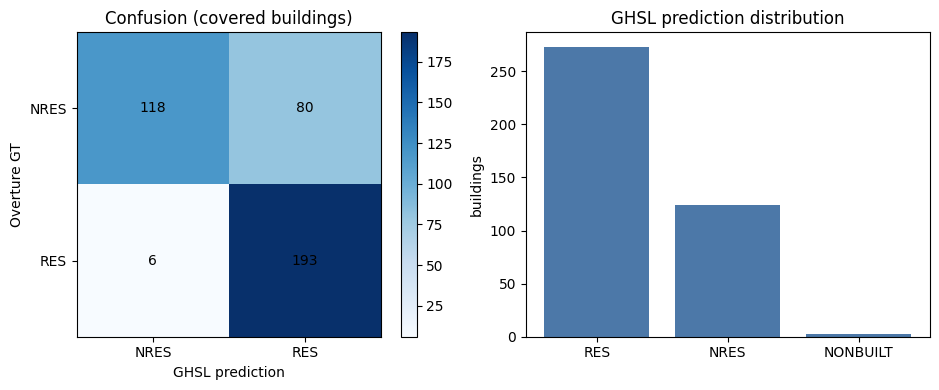

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference/figures/batch_summary.png
{
  "label_definition_note": "GHSL is predictor only; GT is resi_def_v1 / Overture class",
  "product": "GHS-BUILT-C FUN R2023A 10m ESRI:54009",
  "aggregation": "pixel majority among codes {1,2} under footprint mask; centroid fallback",
  "aoi_id": "NYC_NE",
  "n_sample": 400,
  "coverage": 0.9925,
  "agreement_on_covered": 0.783375314861461,
  "prediction_counts": {
    "RES": 273,
    "NRES": 124,
    "NONBUILT": 3
  },
  "mixed_footprints_in_aoi": 425,
  "mixed_both_res_nres": 395,
  "paths": {
    "batch": "outputs/ghsl_inference/sample_building_ghsl_predictions.parquet",
    "demo": "outputs/ghsl_inference/demo_buildings.parquet",
    "mixed": "outputs/ghsl_inference/mixed_examples.parquet",
    "figures": "outputs/ghsl_inference/figures"
  }
}


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Confusion among covered
cov = batch[batch["ghsl_covered"]].copy()
if len(cov):
    ct = pd.crosstab(cov["gt_label"], cov["ghsl_prediction"], dropna=False)
    im = axes[0].imshow(ct.values, cmap="Blues")
    axes[0].set_xticks(range(len(ct.columns)))
    axes[0].set_xticklabels(ct.columns)
    axes[0].set_yticks(range(len(ct.index)))
    axes[0].set_yticklabels(ct.index)
    axes[0].set_xlabel("GHSL prediction")
    axes[0].set_ylabel("Overture GT")
    axes[0].set_title("Confusion (covered buildings)")
    for (ii, jj), val in np.ndenumerate(ct.values):
        axes[0].text(jj, ii, int(val), ha="center", va="center", color="black")
    fig.colorbar(im, ax=axes[0], fraction=0.046)
else:
    axes[0].text(0.5, 0.5, "no covered buildings", ha="center")
    axes[0].set_axis_off()

vc = batch["ghsl_prediction"].value_counts()
axes[1].bar(vc.index.astype(str), vc.values, color="#4c78a8")
axes[1].set_title("GHSL prediction distribution")
axes[1].set_ylabel("buildings")
fig.tight_layout()
summary_png = FIG / "batch_summary.png"
fig.savefig(summary_png, dpi=140, bbox_inches="tight")
plt.show()
print("Wrote", summary_png)

# Persist
batch_path = OUT / "sample_building_ghsl_predictions.parquet"
batch.to_parquet(batch_path, index=False)
demo_path = OUT / "demo_buildings.parquet"
demo_table.to_parquet(demo_path, index=False)

snapshot = {
    "label_definition_note": "GHSL is predictor only; GT is resi_def_v1 / Overture class",
    "product": "GHS-BUILT-C FUN R2023A 10m ESRI:54009",
    "aggregation": "pixel majority among codes {1,2} under footprint mask; centroid fallback",
    "aoi_id": aoi,
    "n_sample": int(len(batch)),
    "coverage": float(batch["ghsl_covered"].mean()) if len(batch) else None,
    "agreement_on_covered": float(covered["agree"].mean()) if len(covered) else None,
    "prediction_counts": batch["ghsl_prediction"].value_counts().to_dict(),
    "mixed_footprints_in_aoi": int(len(mixed_df)) if "mixed_df" in dir() else None,
    "mixed_both_res_nres": int(((mixed_df.n_res > 0) & (mixed_df.n_nres > 0)).sum()) if "mixed_df" in dir() and len(mixed_df) else None,
    "paths": {
        "batch": str(batch_path.relative_to(ROOT)),
        "demo": str(demo_path.relative_to(ROOT)),
        "mixed": "outputs/ghsl_inference/mixed_examples.parquet",
        "figures": str(FIG.relative_to(ROOT)),
    },
}
(OUT / "snapshot.json").write_text(json.dumps(snapshot, indent=2))
print(json.dumps(snapshot, indent=2))


## 6. Takeaways

1. **GHSL → building type** here means **binary RES / NRES**, not the 10-class Overture taxonomy.
2. Steps are mechanical: reproject → window tile → mask footprint → majority of codes `1` vs `2`.
3. Footprints often span **multiple** GHSL codes (§3b) — majority vote is the building label; ties go RES.
4. Codes `0` / `255` are **abstentions**, not non-residential negatives.
5. This is the baseline the Week-2 CNN is scored against (`validation/run_validation.py`).
6. Locked study GT remains Overture `resi_def_v1` — never swap GHSL in as ground truth.

**Next.** Full AOI scoreboard: `python validation/run_validation.py` · deeper product EDA: notebook 10.


In [23]:
# Close mosaic datasets opened in the demo cell
try:
    mosaic.close()
except Exception:
    pass
print("Done. Artifacts in", OUT)


Done. Artifacts in /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_inference
